<a href="https://colab.research.google.com/github/aashwill/tokens-to-megawatts/blob/main/day4_meet_the_real_trace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 4: Meet the real trace (Alibaba cluster-trace-gpu-v2026)

**Tokens to Megawatts, Layer 0, Day 4** · about 70 minutes

Days 1–3 used synthetic data. Today you meet the real thing, and you do it the way a planner does with any new data source: **read the docs, predict what will go wrong, then load the smallest possible slice and check your predictions.** Same rules: one cell at a time, predict before you run, ✏️ exercises before the solutions at the bottom.

**One big surprise up front.** Day 3's practice trace was a *job table* (one row per job, times in seconds). The real v2026 trace is mostly an **hourly pod table**: one row per pod per hour, with GPU-hours already computed. That changes several of the Day 3 cleaning steps, and Part 2 walks through exactly how.

| Part | Topic | Time |
|---|---|---|
| 1 | Read the docs (with a reading guide) | 15 min |
| 2 | Grain: job table vs hourly pod table | 8 min |
| 3 | Map Day 3's cleaning steps onto the real columns | 8 min |
| 4 | Size reality: why you can't just download it | 6 min |
| 5 | Write your predictions **before** loading | 6 min |
| 6 | Load one hour (and only one hour) | 10 min |
| 7 | The three numbers: installed, allocated, used | 8 min |
| 8 | Sanity checks on one hour | 6 min |
| 9 | Four questions, issues log, wrap-up | 3 min |

---
## Part 1: Read the docs

Open these three pages in another tab. They are short (the schema page is the long one, about 5 minutes):

1. **Release README:** https://github.com/alibaba/clusterdata/blob/master/cluster-trace-gpu-v2026/README.md
2. **Schema:** https://github.com/alibaba/clusterdata/blob/master/cluster-trace-gpu-v2026/docs/schema.md
3. **Download page:** https://github.com/alibaba/clusterdata/blob/master/cluster-trace-gpu-v2026/docs/data_download.md

Optional, for later: the OSDI '26 paper, *Heterogeneity at Hyperscale*, linked from the README. Skim the figures; they're the analyses you'll partly recreate.

**Reading guide.** Answer these in the cell below as you read. Short answers are fine.

1. How many tables are there, and which one would you use for **demand**? Which for **supply**?
2. What does **one row** of `asi_opensource_pod_hourly` describe?
3. How is time stored? Are there calendar dates?
4. What unit is `gpu_request`? What unit is `used_gpu_hours`?
5. Which column tells you high-priority vs low-priority (spot) work?
6. What filter do the authors say most of their analyses apply?
7. How big is the pod table download?

✏️ **Your answers** (double-click to edit):

1.4 tables; demand: pod_hourly; supply: server_hourly
2. A pod is a small, isolated environment where an application runs; One row describes one pod observed on a GPU server during one hour.
3. Time is relative. day=0 is the trace start day and no calendar days
4. gpu_request: gpu_count, used_gpu_hours: hours
5. priority_class
6. Most figure reproduction scripts filter to GPU-requesting pods with gpu_request > 0.
7. 351 GB

---
## Part 2: Grain. What does one row mean?

**Grain** is the first question to ask about any table: *what does one row represent?* You already know this from SQL: joining an orders table to an order-lines table without thinking about grain is how totals double.

| | Day 3 practice trace | Real v2026 `pod_hourly` |
|---|---|---|
| One row is | one job | one pod **in one hour** |
| Time | `submit_time`, `start_time`, `end_time` in seconds | `day` (0–184) and `hour` (00–23) partitions |
| GPU size | `plan_gpu` in percent (100 = 1 GPU) | `gpu_request` in GPUs (1.0 = 1 GPU, fractions allowed) |
| GPU-hours | you computed it: GPUs × duration | given: `used_gpu_hours` per pod-hour |
| Job length | `end - start` | count the hours a pod appears, or use `job_execution_summary.duration_hours` |

A pod is roughly one running copy of a job's container. A training job on 4 servers might be 4 pods.

Here's the same tiny job in both shapes, so you can see the reshaping with your own eyes:

In [3]:
import pandas as pd
import numpy as np

# Day 3 grain: one row per job
job = pd.DataFrame({"job_id": ["job_0001"], "gpus": [4.0],
                    "start_hour": [10], "end_hour": [13]})          # ran 10:00 → 13:00
job["gpu_hours"] = job["gpus"] * (job["end_hour"] - job["start_hour"])
print(job, "\n")

# v2026 grain: one row per pod per hour it was alive
pod_hours = pd.DataFrame({
    "pod_id": "pod_a", "day": "0", "hour": ["10", "11", "12"],
    "gpu_request": 4.0, "used_gpu_hours": 4.0,
})
print(pod_hours, "\n")
print("same GPU-hours?", job["gpu_hours"].sum() == pod_hours["used_gpu_hours"].sum())

     job_id  gpus  start_hour  end_hour  gpu_hours
0  job_0001   4.0          10        13       12.0 

  pod_id day hour  gpu_request  used_gpu_hours
0  pod_a   0   10          4.0             4.0
1  pod_a   0   11          4.0             4.0
2  pod_a   0   12          4.0             4.0 

same GPU-hours? True


Two consequences, both good news:

- **"GPUs in use per hour"** (the core demand curve for Layer 1) is now just a `GROUP BY day, hour` with a `SUM`. On Day 2 you had to warn that booking a job on its submit day was a simplification; the hourly grain removes it.
- **Counting rows no longer counts jobs.** `len(df)` is pod-hours. To count pods, use `nunique()` on `pod_id`. To count jobs, `workload_id` is the closest thing, and it can be null.

---
## Part 3: Map Day 3's steps onto the real columns

Every Day 3 step still applies. Some get easier, some change, and one gets a new twist.

✏️ **Exercise 1.** Fill in the empty cells of this table (double-click to edit). Use the schema page. Two rows are done for you.

| Day 3 step | Day 3 column(s) | v2026 column(s) | What changes? |
|---|---|---|---|
| Duplicates | whole row, `job_id` | `pod_id` + `day` + `hour` | The key is now 3 columns: a pod should appear once per hour |
| Label cleanup | `gpu_type` (case, spaces, aliases) |gpu_spec_public| given normalized values but check it using value_counts(dropna=False) to confirm
| Missing labels → `UNKNOWN` | `gpu_type` |  job_type, model_type|
| Right-censored running jobs | `end_time` is null | state_public| |
| Units | `plan_gpu / 100` | | |
| GPU-hours | `gpus × duration_s / 3600` | `used_gpu_hours` | Given per pod-hour; your job is to check it, not compute it |
| Flag bad rows | `duration_s < 0`, `gpus <= 0` | | |
| Lookup join (specs) | `gpu_type` → `gpu_specs.csv` | | |
| Capacity table | `gpu_capacity.csv` | | |
| Long queues = unmet demand | `wait_s` | | |

| Day 3 step | v2026 column(s) | What changes? |
|---|---|---|
| Label cleanup | `gpu_spec_public`, `job_type_public`, `model_type_public`, `state_public`, `priority_class` | Already normalized into public buckets, so expect little case/alias mess. Still run `value_counts(dropna=False)` to confirm |
| Missing labels | same columns | Missing is already labelled `unknown` for job and model type; `workload_id` can be null |
| Right-censored | `day`/`hour` near 0 and 184 | No end time to fill. Instead, pods alive at the trace edges have truncated histories, and `job_execution_summary.duration_hours` is censored for them |
| Units | `gpu_request` | Already GPUs, not percent. **No `/ 100`**. Fractional values are fractional GPUs |
| Flag bad rows | `gpu_request <= 0`, negative or oversized `used_gpu_hours` | Zero-GPU pods are documented and expected: filter them, don't call them bad |
| Lookup join | `gpu_spec_public` → your own spec table (TDP, memory) | You'll need to build it, and the buckets are anonymized, so mapping to real watts is an assumption you state |
| Capacity table | `server_hourly.gpu_count` by `gpu_spec_public` | Real supply, hour by hour, instead of a made-up CSV |
| Long queues | `state_public == "Pending"`, `schedule_delay_sec` | Pending pods are unmet demand; delay is in seconds and can be null |

---
## Part 4: Size reality

From the download page, the four ZIP archives are:

In [4]:
archives = pd.DataFrame({
    "archive": ["pod_hourly", "server_hourly", "network_hourly", "job_execution_summary"],
    "bytes":   [351_803_513_445, 3_080_121_387, 203_904_100, 1_188_295_031],
})
archives["gb"] = archives["bytes"] / 1e9
archives

,archive,bytes,gb
0,pod_hourly,351803513445,351.803513
1,server_hourly,3080121387,3.080121
2,network_hourly,203904100,0.203904
3,job_execution_summary,1188295031,1.188295


The pod table is about **352 GB compressed**. A free Colab machine has roughly 100 GB of disk and 12 GB of memory; a laptop isn't much better. Downloading it whole is not an option, and it doesn't need to be.

The good news is in the folder layout: `pod_hourly/day=<day>/hour=<hour>/part-000.parquet`. Each hour is its own file. That's called **partitioning**, and it means you can fetch only the hours you need. A ZIP file also keeps a table of contents at its end, so a tool called `remotezip` can read that table of contents over the internet and download individual files from inside the ZIP without fetching the rest.

✏️ **Exercise 2.** Back-of-envelope, the way you'd size a warehouse:
1. The trace has 185 days × 24 hours. Roughly how many GB is one hour of `pod_hourly`?
2. How much would one full week cost to download? One hour per day across all 185 days?
3. Which sample would you choose for a **six-month demand trend**, and which for a **daily peak-vs-average** chart? Why might they be different?

In [2]:
# ✏️ Exercise 2: your code here
per_hour_gb = 351.8 / (185 * 24)
print(f"one hour ≈ {per_hour_gb:.3f} GB (~{per_hour_gb * 1000:.0f} MB)")
print(f"one week ≈ {per_hour_gb * 24 * 7:.1f} GB")
print(f"one hour per day for 185 days ≈ {per_hour_gb * 185:.1f} GB")
# A six-month trend needs breadth: one or two fixed hours every day (same hour each day so it's comparable).
# Peak vs average needs depth: every hour, but only for a week or two.
# Real fleets are often sampled like this: a thin long series plus a few dense windows.
# Use pod_parts["mb"] once you have it: real hours vary, so recompute with actual sizes.

one hour ≈ 0.079 GB (~79 MB)
one week ≈ 13.3 GB
one hour per day for 185 days ≈ 14.7 GB


---
## Part 5: Predictions, before loading a single row

This is the most important habit of the day. Writing predictions first turns "I looked at the data" into "I tested specific hypotheses", which is a much better story in an interview and catches more problems.

✏️ **Exercise 3.** Write at least **six** issues you expect to find, using what you learned on Day 3 and what the schema says. For each one, write how you'd detect it in one line of pandas. A few prompts:

- Which columns does the schema say *can be null*?
- What does the schema say about pods with zero GPU request?
- What state buckets exist, and which ones should count as demand?
- Is a pod's `used_gpu_hours` allowed to be bigger than its `gpu_request`?
- The partition columns are in the **folder path**. Will they be inside the file?
- What timezone is `hour` in?

| # | Expected issue | How I'll detect it |
|---|---|---|
| 1 |null workload_id | pods["workload_id"].isna().mean() |
| 2 | Demand|anything except Unknown |
| 3 | used_gpu_hours>gpu_request|(g["used_gpu_hours"] > g["gpu_request"]).sum() |
| 4 |no timezone for hour |use an assumption |
| 5 | day/hour not inside the parquet file (they're in the folder path)| pods.columns to understand which columns the dataset has|
| 6 |First and last days are partial (Day 2 partial-week trap) |file_size in pod_parts function() to determine the size of every day |

---
## Part 6: Load one hour

Now the moment of truth. First, install `remotezip` and **list what's inside the ZIP without downloading it**. Even this is a data check: does every day and hour exist?

> If the cells in this part fail with a network or "range" error, the storage server may not allow partial downloads from Colab. Fallback: download the small `asi_opensource_network_hourly.zip` (204 MB) or `asi_opensource_job_execution_summary.zip` (1.2 GB) in full with `!wget`, and do Exercise 3's checks on that instead. Note the failure in your issues log either way.

In [6]:
!pip install -q remotezip

In [7]:
import re, io
from remotezip import RemoteZip

BASE = "https://tre-clusterdata.oss-cn-hangzhou.aliyuncs.com/cluster-trace-gpu-v2026/data/"

def list_parts(zip_name):
    # Read only the ZIP's table of contents and return one row per parquet file.
    rows = []
    with RemoteZip(BASE + zip_name) as z:
        for info in z.infolist():
            m = re.search(r"day=(\d+)/hour=(\d+)/.*\.parquet$", info.filename)
            if m:
                rows.append({"day": int(m[1]), "hour": int(m[2]),
                             "member": info.filename, "mb": info.file_size / 1e6})
    return pd.DataFrame(rows)

pod_parts = list_parts("asi_opensource_pod_hourly.zip")
print(len(pod_parts), "hourly files | expected", 185 * 24)
pod_parts["mb"].describe()

4440 hourly files | expected 4440


,mb
count,4440.000000
mean,79.234823
std,10.957942
min,37.298863
25%,69.735866
50%,80.699597
75%,88.049888
max,111.942754


Check the count against 185 × 24 = 4,440. If it's short, find which hours are missing; on Day 2 you learned that gaps break rolling averages. One way: build every (day, hour) pair and anti-join, exactly like Day 3 Part 6.

In [8]:
all_hours = pd.MultiIndex.from_product([range(185), range(24)], names=["day", "hour"]).to_frame(index=False)
missing = all_hours.merge(pod_parts[["day", "hour"]], how="left", indicator=True)
missing = missing[missing["_merge"] == "left_only"]
print(len(missing), "missing hours")
missing.head()

0 missing hours


,day,hour,_merge


File size per hour is itself a rough **demand signal**: more pods, more rows, bigger file. Plot it before loading any rows. You get a six-month shape of the trace for free.

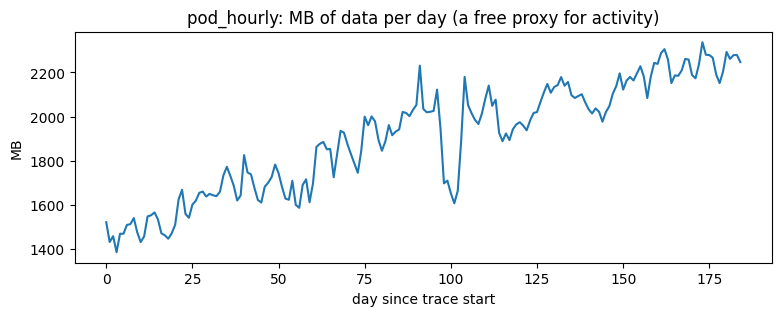

In [9]:
import matplotlib.pyplot as plt

daily_mb = pod_parts.groupby("day")["mb"].sum()
ax = daily_mb.plot(figsize=(9, 3), title="pod_hourly: MB of data per day (a free proxy for activity)")
ax.set_xlabel("day since trace start"); ax.set_ylabel("MB"); plt.show()

Now fetch **one** hour. Pick a mid-trace weekday-ish day and a busy hour; the default below is day 60, hour 14. The fetch is about the size shown in `mb`, so expect it to take a little while.

Then fetch the **same hour** of `server_hourly` (that file is small). Pods give you demand; servers give you supply.

In [17]:
DAY, HOUR = 100, 11

def fetch_part(zip_name, parts, day, hour):
    # Download one parquet file from inside the remote ZIP and add day/hour from its path.
    member = parts.loc[(parts["day"] == day) & (parts["hour"] == hour), "member"].iloc[0]
    with RemoteZip(BASE + zip_name) as z:
        df = pd.read_parquet(io.BytesIO(z.read(member)))
    print(member, "→", df.shape, "| day/hour inside file?", {"day", "hour"} <= set(df.columns))
    return df.assign(day=day, hour=hour)      # partition values live in the folder path

pods = fetch_part("asi_opensource_pod_hourly.zip", pod_parts, DAY, HOUR)
server_parts = list_parts("asi_opensource_server_hourly.zip")
servers = fetch_part("asi_opensource_server_hourly.zip", server_parts, DAY, HOUR)

asi_opensource_pod_hourly/day=100/hour=11/part-000.parquet → (1575341, 23) | day/hour inside file? False
asi_opensource_server_hourly/day=100/hour=11/part-000.parquet → (31489, 6) | day/hour inside file? False


Save both locally so you never pay for the download twice. Parquet keeps the column types; CSV would lose them (Day 2's date-parsing trap).

In [18]:
pods.to_parquet(f"pods_d{DAY}_h{HOUR}.parquet")
servers.to_parquet(f"servers_d{DAY}_h{HOUR}.parquet")
# Next session: pods = pd.read_parquet("pods_d60_h14.parquet")

### First look: the Day 3 profile, on real data
Same five minutes as Day 3 Part 1. Go back to your predictions table as you read the output.

In [12]:
print(pods.shape)
pods.info()

(1244924, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1244924 entries, 0 to 1244923
Data columns (total 25 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   pod_id                     1244924 non-null  object 
 1   workload_id                884214 non-null   object 
 2   server_id                  1244924 non-null  object 
 3   cluster_id                 1244924 non-null  object 
 4   state_public               1244924 non-null  object 
 5   gpu_spec_public            1244924 non-null  object 
 6   server_gpu_count           1244924 non-null  int64  
 7   server_cpu_capacity_cores  1244924 non-null  int64  
 8   priority_class             1244924 non-null  object 
 9   job_type_public            1244924 non-null  object 
 10  model_type_public          1244924 non-null  object 
 11  is_genai_request           1244924 non-null  bool   
 12  gpu_request                1244924 non-null  float64
 13

In [13]:
print(pods.isna().sum().sort_values(ascending=False).head(10), "\n")
print("pod-hours:", len(pods), "| distinct pods:", pods["pod_id"].nunique(),
      "| distinct workloads:", pods["workload_id"].nunique(), "| servers:", pods["server_id"].nunique())

avg_gpu_sm_util         1163502
avg_gpu_mem_gib         1143321
workload_id              360710
ready_delay_sec           36226
ready_status              36226
schedule_delay_sec        36226
avg_cpu_request_util      23505
avg_memory_util           11375
pod_id                        0
priority_class                0
dtype: int64 

pod-hours: 1244924 | distinct pods: 1244923 | distinct workloads: 56059 | servers: 29358


In [19]:
for col in ["state_public", "priority_class", "job_type_public", "model_type_public", "gpu_spec_public"]:
    print(pods[col].value_counts(dropna=False), "\n")

state_public
Unknown    1575341
Name: count, dtype: int64 

priority_class
Other    1204417
HP        336275
LP         34649
Name: count, dtype: int64 

job_type_public
unknown              1467760
online_inference       67718
offline_inference      29272
training                8742
dev                     1701
other                    148
Name: count, dtype: int64 

model_type_public
unknown      1467541
genai          49368
rec            43511
cv              9800
embedding       3963
dev             1158
Name: count, dtype: int64 

gpu_spec_public
A10      361457
L20      270838
XPU-B    228055
H20      221354
XPU-E    146325
XPU-C    109400
XPU-A     92910
A100      90345
XPU-D     22910
A800      18377
H800      11730
A30        1640
Name: count, dtype: int64 



In [15]:
pods[["gpu_request", "used_gpu_hours", "avg_gpu_sm_util", "schedule_delay_sec"]].describe()

,gpu_request,used_gpu_hours,avg_gpu_sm_util,schedule_delay_sec
count,1.244924e+06,1.244924e+06,81422.000000,1.208698e+06
mean,1.090920e-01,9.303347e-02,31.584706,2.710846e+02
std,6.413536e-01,5.681709e-01,77.923389,3.271038e+03
min,0.000000e+00,0.000000e+00,0.000000,-1.000000e+00
25%,0.000000e+00,0.000000e+00,1.562500,0.000000e+00
50%,0.000000e+00,0.000000e+00,10.777778,0.000000e+00
75%,0.000000e+00,0.000000e+00,34.616419,2.000000e+01
max,1.600000e+01,1.600000e+01,1113.926410,8.636600e+04


Now mark each prediction from Part 5: ✅ confirmed, ❌ wrong, or ❓ can't tell from one hour. Wrong predictions are the valuable ones; write down what surprised you.

---
## Part 7: The three numbers every capacity review starts from

- **Installed**: GPUs physically present (from `servers`). Supply.
- **Allocated**: GPUs reserved by pods (sum of `gpu_request`). What the scheduler sees as taken.
- **Used**: GPUs actually busy (sum of `used_gpu_hours` in a one-hour window equals the average GPUs busy that hour).

The gaps between them are where the money is. Installed minus allocated is **idle or fragmented** capacity. Allocated minus used is **reserved but not working**: a pod asked for 8 GPUs and kept 3 busy. This is the same idea as warehouse labor: headcount on the roster, people clocked in, and units actually processed.

Which pods count as demand? Start with GPU-requesting pods and look at the split by state before deciding:

In [16]:
gpu_pods = pods[pods["gpu_request"] > 0]

by_state = gpu_pods.groupby("state_public", dropna=False).agg(
    pods=("pod_id", "nunique"),
    allocated_gpus=("gpu_request", "sum"),
    used_gpus=("used_gpu_hours", "sum"),
).sort_values("allocated_gpus", ascending=False)
by_state

,pods,allocated_gpus,used_gpus
state_public,,,
Unknown,105726,135811.28,115819.605


Look closely at `Standby` and `Pending`. A pending pod is **unmet demand**: it wants GPUs and hasn't got them (Day 3's long-queue lesson again). A standby pod holds capacity in reserve. Whether each one counts as "demand" is a **planning decision you write down**, not a coding detail.

✏️ **Exercise 4.** By `gpu_spec_public`, compute installed GPUs (from `servers`), allocated GPUs (Running pods only), and used GPUs. Then add `alloc_ratio = allocated / installed` and `use_ratio = used / allocated`. Which GPU type is closest to full? Which has the most reserved-but-idle GPUs?

In [ ]:
# ✏️ Exercise 4: your code here
installed_gpus = servers.groupby("gpu_spec_public")["gpu_count"].sum()

---
## Part 8: Sanity checks on one hour

Day 3's `run_checks()` was written for a job table. Here's the hourly-pod version. **A failing check on real data is not a bug in your code; it's a finding.** Write it in your issues log and decide what to do about it.

In [20]:
def run_pod_hour_checks(pods, servers):
    # Pass/fail checks for one hour of pod_hourly against the same hour of server_hourly.
    results = []
    def check(name, passed, detail=""):
        results.append({"check": name, "passed": bool(passed), "detail": detail})

    g = pods[pods["gpu_request"] > 0]

    dupes = pods.duplicated(["pod_id", "day", "hour"]).sum()
    check("pod appears once per hour", dupes == 0, f"{dupes} duplicate pod-hours")

    check("server_id unique in server table", servers["server_id"].is_unique)

    orphans = set(pods["server_id"].dropna()) - set(servers["server_id"])
    check("every pod's server is in the server table", not orphans, f"{len(orphans)} unknown servers")

    neg = (g[["gpu_request", "used_gpu_hours"]] < 0).any(axis=1).sum()
    check("no negative GPU values", neg == 0, f"{neg} rows")

    over_used = (g["used_gpu_hours"] > g["gpu_request"] * 1.01).sum()
    check("used ≤ requested (1% tolerance)", over_used == 0, f"{over_used} pods used more than requested")

    alloc = (g[g["state_public"] == "Running"].groupby("server_id")["gpu_request"].sum()
               .rename("allocated").reset_index()
               .merge(servers[["server_id", "gpu_count"]], on="server_id", how="inner", validate="one_to_one"))
    over_server = (alloc["allocated"] > alloc["gpu_count"] + 1e-9).sum()
    check("running pods fit on their server", over_server == 0, f"{over_server} servers over-allocated")

    known = {"Standby", "Running", "Pending", "Succeeded", "Failed", "Unknown"}
    odd = set(pods["state_public"].dropna()) - known
    check("state labels are the documented set", not odd, ", ".join(sorted(odd)))

    m = (pods[["server_id", "server_gpu_count"]].drop_duplicates("server_id")
             .merge(servers[["server_id", "gpu_count"]], on="server_id", how="inner"))
    mismatch = (m["server_gpu_count"] != m["gpu_count"]).sum()
    check("pod and server tables agree on GPUs per server", mismatch == 0, f"{mismatch} servers disagree")

    return pd.DataFrame(results)

run_pod_hour_checks(pods, servers)

,check,passed,detail
0,pod appears once per hour,False,1 duplicate pod-hours
1,server_id unique in server table,True,
2,every pod's server is in the server table,True,0 unknown servers
3,no negative GPU values,True,0 rows
4,used ≤ requested (1% tolerance),True,0 pods used more than requested
5,running pods fit on their server,True,0 servers over-allocated
6,state labels are the documented set,True,
7,pod and server tables agree on GPUs per server,True,0 servers disagree


Notice the merge inside the over-allocation check uses `validate="one_to_one"`: the Day 3 habit, now on real data.

✏️ **Exercise 5 (stretch).** Add one check of your own from your Part 5 predictions list. Suggestions: "`gpu_spec_public` on the pod matches the server's `gpu_spec_public`", or "no GPU-requesting pod has a null `gpu_spec_public`".

In [24]:
# ✏️ Exercise 5: your code here

def spec_matches(pods, servers):
    m = (pods[pods["gpu_request"] > 0][["pod_id", "server_id", "gpu_spec_public"]]
           .merge(servers[["server_id", "gpu_spec_public"]], on="server_id", how="inner",
                  suffixes=("_pod", "_server"), validate="many_to_one"))
    bad = (m["gpu_spec_public_pod"] != m["gpu_spec_public_server"]).sum()
    return pd.DataFrame([{"check": "pod GPU type matches its server", "passed": bad == 0,
                          "detail": f"{bad} pods disagree"}])

pd.concat([run_pod_hour_checks(pods, servers), spec_matches(pods, servers)], ignore_index=True)


,check,passed,detail
0,pod appears once per hour,False,1 duplicate pod-hours
1,server_id unique in server table,True,
2,every pod's server is in the server table,True,0 unknown servers
3,no negative GPU values,True,0 rows
4,used ≤ requested (1% tolerance),True,0 pods used more than requested
5,running pods fit on their server,True,0 servers over-allocated
6,state labels are the documented set,True,
7,pod and server tables agree on GPUs per server,True,0 servers disagree
8,pod GPU type matches its server,True,0 pods disagree


---
## Part 9: Four questions, and wrap-up

Imagine Claude Code wrote this block. Answer before you run it:
1. What is the input?
2. What transformation happens?
3. What is the output?
4. How would I know if the result is wrong?

In [34]:
pods.groupby(["gpu_spec_public"]).valuecounts()

,count
state_public,
Unknown,1575341


In [27]:
mix = (
    pods[(pods["gpu_request"] > 0) & (pods["state_public"] == "Running")]
        .groupby(["job_type_public", "priority_class"], as_index=False)["used_gpu_hours"].sum()
        .assign(share=lambda d: d["used_gpu_hours"] / d["used_gpu_hours"].sum())
        .sort_values("share", ascending=False)
)
mix

,job_type_public,priority_class,used_gpu_hours,share


✏️ **Your answers** (double-click to edit):

1. Input:
2. Transformation:
3. Output:
4. How I'd spot a wrong result:

**Start your `DATA_ISSUES.md` today.** Copy your Part 5 predictions table into it, add the ✅ / ❌ / ❓ column and one line per check that failed. This file becomes the "data issues" section of your README, and it's the kind of thing a Google or Meta interviewer will ask about.

**Add to `glossary.md`, in your own words:**
- **Grain:** what one row of a table represents; check it before any join or count
- **Partitioning:** splitting a big table into files by a column (here day and hour) so you can read only what you need
- **Installed / allocated / used:** supply, reserved, and actually busy; the gaps are idle capacity and reserved-but-idle capacity
- **Pending demand:** pods waiting for GPUs; unmet demand that utilization alone hides

**Done today when you can:**
- [ ] Say in one sentence what one row of `pod_hourly` is
- [ ] Explain why you can't download the whole pod table, and how you'll sample it
- [ ] Give the three numbers (installed, allocated, used) for your hour, and what the gaps mean

**Next (Day 5):** decide the sample (which days and hours) and fetch it into one local Parquet folder, then rebuild Day 2's daily peak-vs-average chart on real data.

---
---
## Solutions (try first!)

**Part 1 reading guide**
1. Four: `pod_hourly`, `server_hourly`, `network_hourly`, `job_execution_summary`. Demand: `pod_hourly`. Supply: `server_hourly`.
2. One pod observed on a GPU server during one hour.
3. Relative `day` (0 = trace start) and `hour` (00–23) partitions. No calendar dates.
4. `gpu_request` is in GPUs (1.0 = one full GPU; fractions allowed). `used_gpu_hours` is GPU-hours for that pod in that hour.
5. `priority_class`: `HP`, `LP` (low-priority/spot), `Other`.
6. They filter to GPU-requesting pods: `gpu_request > 0`.
7. About 352 GB compressed (351,803,513,445 bytes).

**Exercise 1**

| Day 3 step | v2026 column(s) | What changes? |
|---|---|---|
| Label cleanup | `gpu_spec_public`, `job_type_public`, `model_type_public`, `state_public`, `priority_class` | Already normalized into public buckets, so expect little case/alias mess. Still run `value_counts(dropna=False)` to confirm |
| Missing labels | same columns | Missing is already labelled `unknown` for job and model type; `workload_id` can be null |
| Right-censored | `day`/`hour` near 0 and 184 | No end time to fill. Instead, pods alive at the trace edges have truncated histories, and `job_execution_summary.duration_hours` is censored for them |
| Units | `gpu_request` | Already GPUs, not percent. **No `/ 100`**. Fractional values are fractional GPUs |
| Flag bad rows | `gpu_request <= 0`, negative or oversized `used_gpu_hours` | Zero-GPU pods are documented and expected: filter them, don't call them bad |
| Lookup join | `gpu_spec_public` → your own spec table (TDP, memory) | You'll need to build it, and the buckets are anonymized, so mapping to real watts is an assumption you state |
| Capacity table | `server_hourly.gpu_count` by `gpu_spec_public` | Real supply, hour by hour, instead of a made-up CSV |
| Long queues | `state_public == "Pending"`, `schedule_delay_sec` | Pending pods are unmet demand; delay is in seconds and can be null |

In [ ]:
# Exercise 2
per_hour_gb = 351.8 / (185 * 24)
print(f"one hour ≈ {per_hour_gb:.3f} GB (~{per_hour_gb * 1000:.0f} MB)")
print(f"one week ≈ {per_hour_gb * 24 * 7:.1f} GB")
print(f"one hour per day for 185 days ≈ {per_hour_gb * 185:.1f} GB")
# A six-month trend needs breadth: one or two fixed hours every day (same hour each day so it's comparable).
# Peak vs average needs depth: every hour, but only for a week or two.
# Real fleets are often sampled like this: a thin long series plus a few dense windows.
# Use pod_parts["mb"] once you have it: real hours vary, so recompute with actual sizes.

**Exercise 3 (one possible list; yours may differ)**

| # | Expected issue | How I'll detect it |
|---|---|---|
| 1 | Pods with `gpu_request == 0` mixed in | `(pods["gpu_request"] == 0).mean()` |
| 2 | Null `workload_id` | `pods["workload_id"].isna().mean()` |
| 3 | Null `schedule_delay_sec` / `ready_delay_sec` | `pods[["schedule_delay_sec", "ready_delay_sec"]].isna().mean()` |
| 4 | `day`/`hour` not inside the parquet file (they're in the folder path) | check `pods.columns` after reading one file |
| 5 | `day`/`hour` stored as text, so `"10" < "9"` sorts wrong | `pods["day"].dtype` |
| 6 | Non-running states (`Standby`, `Pending`, `Succeeded`) holding or wanting GPUs | `value_counts` of `state_public`, then sums by state |
| 7 | `used_gpu_hours` slightly above `gpu_request` (sampling noise) | `(g["used_gpu_hours"] > g["gpu_request"]).sum()` |
| 8 | `unknown` buckets in job and model type | `value_counts(dropna=False)` |
| 9 | Unknown timezone for `hour`, so "peak hour" may be shifted | Not detectable from data; state it as an assumption |
| 10 | First and last days are partial (Day 2 partial-week trap) | file count and size per day in `pod_parts` |

In [ ]:
# Exercise 4
installed = servers.groupby("gpu_spec_public")["gpu_count"].sum().rename("installed")
running = pods[(pods["gpu_request"] > 0) & (pods["state_public"] == "Running")]
allocated = running.groupby("gpu_spec_public")["gpu_request"].sum().rename("allocated")
used = running.groupby("gpu_spec_public")["used_gpu_hours"].sum().rename("used")

three = pd.concat([installed, allocated, used], axis=1).fillna(0)
three["alloc_ratio"] = three["allocated"] / three["installed"]
three["use_ratio"] = three["used"] / three["allocated"]
three["reserved_idle"] = three["allocated"] - three["used"]
three.sort_values("installed", ascending=False)
# pd.concat with axis=1 lines up on the index: a FULL OUTER JOIN on gpu_spec_public.
# A GPU type with installed > 0 but nothing running shows allocated = 0 (fillna), not a missing row.

In [23]:
# Exercise 5 (one option)
def spec_matches(pods, servers):
    m = (pods[pods["gpu_request"] > 0][["pod_id", "server_id", "gpu_spec_public"]]
           .merge(servers[["server_id", "gpu_spec_public"]], on="server_id", how="inner",
                  suffixes=("_pod", "_server"), validate="many_to_one"))
    bad = (m["gpu_spec_public_pod"] != m["gpu_spec_public_server"]).sum()
    return pd.DataFrame([{"check": "pod GPU type matches its server", "passed": bad == 0,
                          "detail": f"{bad} pods disagree"}])

pd.concat([run_pod_hour_checks(pods, servers), spec_matches(pods, servers)], ignore_index=True)

,check,passed,detail
0,pod appears once per hour,False,1 duplicate pod-hours
1,server_id unique in server table,True,
2,every pod's server is in the server table,True,0 unknown servers
3,no negative GPU values,True,0 rows
4,used ≤ requested (1% tolerance),True,0 pods used more than requested
5,running pods fit on their server,True,0 servers over-allocated
6,state labels are the documented set,True,
7,pod and server tables agree on GPUs per server,True,0 servers disagree
8,pod GPU type matches its server,True,0 pods disagree
